In [207]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

database_path = "dimspec_nist_pfas .sqlite"
conn = sqlite3.connect(database_path)
cursor = conn.cursor()

# 1. Database Exploration

## 1.1 Explore the overall structure of the NIST PFAS database.

What information is contained within the NIST PFAS database, and which tables are relevant to PFAS characterization?

Before analyzing PFAS compounds or their mass spectral signatures, it is necessary to understand how the database is organized. The first step is to identify the tables contained within the SQLite database and determine which ones are relevant to answering the research objectives.

In [208]:
cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type='table';
""")

for row in cursor.fetchall():
    print(row)

('config',)
('elements',)
('sqlite_sequence',)
('isotopes',)
('norm_ionization',)
('norm_carriers',)
('norm_additives',)
('norm_vendors',)
('norm_ce_desc',)
('norm_ce_units',)
('norm_voltage_units',)
('norm_ms_types',)
('norm_ms_n_types',)
('norm_fragmentation_types',)
('norm_polarity_types',)
('norm_chromatography_types',)
('norm_column_chemistries',)
('norm_column_positions',)
('norm_duration_units',)
('norm_additive_units',)
('norm_flow_units',)
('carrier_mix_collections',)
('mobile_phases',)
('ms_descriptions',)
('chromatography_descriptions',)
('ms_methods',)
('carrier_aliases',)
('additive_aliases',)
('carrier_mixes',)
('carrier_additives',)
('norm_generation_type',)
('norm_source_types',)
('compound_categories',)
('norm_analyte_alias_references',)
('compounds',)
('compound_aliases',)
('compound_fragments',)
('annotated_fragments',)
('fragment_inspections',)
('norm_fragments',)
('fragment_aliases',)
('fragment_sources',)
('norm_sample_classes',)
('norm_ion_states',)
('norm_peak_c

**Results** 

The query returned over sixty tables. The tables most relevant to this project were identified as: samples, compounds, peaks, compound_fragments, ms_data,annotated_fragments
    

**Interpretation** 

The NIST PFAS database is organized as a relational database, meaning that different types of information are stored separately and connected through common identifiers. Rather than storing all information in a single table, the database separates sample information, compound identities, chromatographic peaks, and mass spectral data into individual tables.

**Key Takeaway**

The database contains all the information necessary to characterize PFAS samples, but the data are distributed across multiple related tables that must later be connected using SQL joins.

## 1.2 Characterize the Relevant Tables

What chemical information is stored for each compound in the database, and how extensive is the compound reference library?

The compounds table was examined to understand the chemical reference information available within the NIST PFAS database. In addition to inspecting representative entries, the total number of compounds was determined to characterize the scope of the reference library.

In [186]:
cursor.execute("""
SELECT id, name, formula, fixedmass
FROM compounds
""")

for row in cursor.fetchall():
    print(row)

(1, '1H-Perfluoro-3,3-bis(trifluoromethyl)hexyne', 'C8HF13', 343.9870669)
(2, 'Bis(heneicosafluorodecyl)phosphinic acid', 'C20H9F34O2P', 957.9797256)
(3, 'Tris(2-(perfluorododecyl)ethyl)phosphate', 'C42H12F75O4P', 2035.927562)
(4, '2-Chloro-2-propenoic acid 3,3,4,4,5,5,6,6,6-nonafluorohexyl ester', 'C9H6ClF9O2', 351.9912611)
(5, 'Bicyclo[2.2.1]hept-2-ene, 5,5,6-trifluoro-6-(heptafluoropropoxy)-', 'C10H6F10O', 332.025897)
(6, '3,3,4-Trifluoro-4-(heptafluoropropoxy)tricyclo[4.2.1.0~2,5~]non-7-ene', 'C12H8F10O', 358.0415471)
(7, '5-(Nonafluorobutyl)bicyclo[2.2.1]hept-2-ene', 'C11H9F9', 312.0560543)
(8, '3-(Heptafluorobutyryl)camphor', 'C14H15F7O2', 348.0960273)
(9, 'Perfluorobutylsulfonamide', 'C4H2F9NO2S', 298.9662533)
(10, 'N-(3,4-Dichlorophenyl)-2,2,3,3,4,4,4-heptafluorobutanamide', 'C10H4Cl2F7NO', 356.9558166)
(11, 'N-(3,5-Dichlorophenyl)-2,2,3,3,4,4,4-heptafluorobutanamide', 'C10H4Cl2F7NO', 356.9558166)
(12, '2-Propenoic acid, 2-methyl-, 2-[[[[5-[[[2-[ethyl[(heptadecafluorooctyl)sulf

**Results** 

The first ten entries included fluorinated compounds such as:
    1H-Perfluoro-3,3-bis(trifluoromethyl)hexyne
    Bis(heneicosafluorodecyl)phosphinic acid
    Tris(2-(perfluorododecyl)ethyl)phosphate
    Perfluorobutylsulfonamide

Each entry included their unique compound ID, chemical name, molecular formula, and exact (monoisotopic) mass

**Interpretation** 

The **compounds** table functions as a reference library rather than experimental data. Each row represents a unique fluorinated compound and provides the molecular information required for compound identification. The diversity of compounds indicates that the database includes not only common PFAS but also precursor compounds and other fluorinated substances.

The compounds table provides the chemical identities that will later be linked to experimental observations in the LC-MS/MS data.

In [126]:
cursor.execute("""
SELECT COUNT(*)
FROM compounds;
""")

print(f"Total compounds: {cursor.fetchone()[0]}")

Total compounds: 4967


**Results** 

The compounds table functions as a chemical reference library rather than a table of experimental observations. Each row corresponds to a unique fluorinated compound and provides the molecular information required for compound identification, including its chemical name, molecular formula, and exact (monoisotopic) mass. With 4,967 unique compounds, the database provides a broad reference library extending beyond commonly targeted PFAS analytes. This large reference library includes a wide range of fluorinated compounds and potential precursors, making it well suited for computational analyses and future AI/ML applications aimed at identifying both known and emerging PFAS.

**Key takeaways** 

The compounds table serves as the chemical foundation of the NIST PFAS database, providing a large reference library of 4,967 compounds that can be linked to experimental LC-MS/MS measurements for downstream characterization, comparative analysis, and AI-assisted PFAS identification.

## 1.3 Determine relationships between tables

How are the relevant tables related, and how can these relationships be used to integrate sample, compound, and LC-MS/MS information?

The foreign key relationships among the relevant tables were examined to determine how different types of information are connected within the NIST PFAS database. Understanding these relationships is essential for constructing SQL JOIN statements that combine sample metadata, chromatographic peaks, compound identities, and mass spectral information.

In [209]:
cursor.execute("PRAGMA foreign_key_list(peaks);")

for row in cursor.fetchall():
    print(row)

(0, 0, 'norm_peak_confidence', 'identification_confidence', 'id', 'CASCADE', 'RESTRICT', 'NONE')
(1, 0, 'norm_ion_states', 'ion_state', 'id', 'CASCADE', 'RESTRICT', 'NONE')
(2, 0, 'conversion_software_peaks_linkage', 'conversion_software_peaks_linkage_id', 'id', 'CASCADE', 'RESTRICT', 'NONE')
(3, 0, 'samples', 'sample_id', 'id', 'CASCADE', 'CASCADE', 'NONE')


**Results** 

The sample_id column inside the peaks table points to the id column inside the samples table.

| Table   | Column      | Connects To  |
| ------- | ----------- | ------------ |
| `peaks` | `sample_id` | `samples.id` |

Each row in the peaks table contains a sample_id, which identifies the sample from which that chromatographic peak was detected.

In [210]:
cursor.execute("PRAGMA foreign_key_list(compound_fragments);")

for row in cursor.fetchall():
    print(row)

(0, 0, 'annotated_fragments', 'annotated_fragment_id', 'id', 'CASCADE', 'CASCADE', 'NONE')
(1, 0, 'compounds', 'compound_id', 'id', 'CASCADE', 'SET NULL', 'NONE')
(2, 0, 'peaks', 'peak_id', 'id', 'CASCADE', 'CASCADE', 'NONE')


**Results**

The compound_fragments table contains three linking columns:

| Table                | Linking Column          | References               |
| -------------------- | ----------------------- | ------------------------ |
| `compound_fragments` | `peak_id`               | `peaks.id`               |
| `compound_fragments` | `compound_id`           | `compounds.id`           |
| `compound_fragments` | `annotated_fragment_id` | `annotated_fragments.id` |

The compound_fragments table acts as a bridge between chromatographic peaks and compound identities. Each record links a detected peak to a specific compound and, when available, to its corresponding annotated fragment information. This table is therefore central to identifying which compounds are associated with the detected LC-MS/MS peaks.

Together, these relationships establish the following analytical progression:
    
    samples → Where did the data come from?
    
    peaks → What signals were detected?
    
    compound_fragments → Which compounds do those signals correspond to?
    
    ms_data → What does the detailed mass spectrum of each signal look like?


In [211]:
cursor.execute("PRAGMA foreign_key_list(ms_data);")

for row in cursor.fetchall():
    print(row)

(0, 0, 'peaks', 'peak_id', 'id', 'CASCADE', 'CASCADE', 'NONE')


The ms_data table contains a peak_id column that links each mass spectral measurement to its corresponding chromatographic peak in the peaks table.

| Table     | Linking Column | References |
| --------- | -------------- | ---------- |
| `ms_data` | `peak_id`      | `peaks.id` |

This relationship allows the detailed mass spectral measurements stored in the ms_data table to be associated with the chromatographic peak from which they were generated. As a result, each detected peak can be connected to its corresponding LC-MS/MS spectral information for further analysis.

## 1.4 Compound Naming Convention

How are PFAS compounds represented in the database?

In [213]:
cursor.execute("""
SELECT name
FROM compounds
WHERE name LIKE '%PF%'
LIMIT 30;
""")

for row in cursor.fetchall():
    print(row)

('Hydrogen-substituted perfluoro 3,6-dioxaoctane sulfonic acid (H-PFO2OS)',)
('Hydrogen-substituted perfluoro 3,6-dioxadecane sulfonic acid (H-PFO2DS)',)
('Hydrogen-substituted perfluoro 3,6-dioxanonane sulfonic acid (H-PFO2NS)',)


**Results**

Only three compounds were returned:
    H-PFO2OS
    H-PFO2DS
    H-PFO2NS

**Interpretation**

Searching for the string "PF" identified very few compounds, indicating that the database primarily stores compounds using systematic chemical names rather than common PFAS abbreviations such as PFOS or PFOA. Consequently, identifying PFAS compounds cannot rely solely on text-based searches and instead requires linking compounds to experimental observations through relational queries.

**Key Takeaway**

PFAS compounds are primarily represented by systematic nomenclature, making relational database queries more appropriate than simple keyword searches.

# 2 DATABASE CHARACTERIZATION

## 2.1 Extract PFAS sample information

Which PFAS compounds are associated with each sample, and what experimental information can be retrieved by linking the relevant tables?

The relationships identified in the previous section were used to join the samples, peaks, compound_fragments, and compounds tables. This allowed the retrieval of sample names, identified compounds, and their corresponding precursor ion (MS1) masses.

In [214]:
cursor.execute("""
SELECT DISTINCT
    s.description AS sample,
    c.name AS compound,
    p.precursor_mz
FROM samples s
JOIN peaks p
ON s.id = p.sample_id
JOIN compound_fragments cf
ON p.id = cf.peak_id
JOIN compounds c
ON cf.compound_id = c.id
LIMIT 20;
""")

for row in cursor.fetchall():
    print(row)

('3M 1989 AFFF', 'N-Hydroxyethyldimethylammoniopropyl perfluorohexanesulfonamide', 529.0815)
('3M 1989 AFFF', 'N-Trimethylammoniopropyl perfluorohexane sulfonamide', 499.0714)
('3M 1989 AFFF', 'N-Hydroxyethyldimethylammoniopropyl perfluorohexanesulfonamidoethanol', 573.1061)
('3M 1993a AFFF', 'N-Dimethyl ammonio propyl perfluoropropane sulfonamido propanoic acid', 407.0863)
('3M 1993a AFFF', '3-(N-(3-(dimethylamino)propyl)-perfluoropentylsulfonamido)propanoic acid', 507.0788)
('3M 1993a AFFF', 'N-Trimethylammoniopropyl perfluorohexane sulfonamido propanoic acid', 571.0906)
('3M 1993a AFFF', 'N-[3-(Dimethylamino)propyl]-N-[(tridecafluorohexyl)sulfonyl]-beta-alanine', 557.0744)
('3M 1993a AFFF', 'N-[3-(Dimethylamino)propyl]-N-[(nonafluorobutyl)sulfonyl]-beta-alanine', 457.0823)
('3M 1993a AFFF', 'Perfluoropentane sulfonamido amine', 435.0581)
('3M 1993b AFFF', 'N-Dimethyl ammonio propyl perfluoropropane sulfonamido propanoic acid', 407.0863)
('3M 1993b AFFF', '3-(N-(3-(dimethylamino)prop

**Results** 

The SQL JOIN successfully linked information stored across four tables. For each detected compound, the query returned:
    - The sample in which the compound was detected
    - The identified compound name
    - The corresponding precursor ion mass-to-charge ratio (precursor_mz)

The output shows that individual samples contain multiple detected PFAS compounds. For example, the sample 3M 1989 AFFF contains compounds such as Perfluorooctanesulfonic acid (PFOS), Perfluorooctanoic acid (PFOA), Perfluorohexanesulfonic acid (PFHxS), and several fluorotelomer- and sulfonamide-related compounds, each with its associated precursor ion mass. Similar patterns are observed for other AFFF formulations, including 3M 1993a AFFF, 3M 1998 AFFF, and National Foam AFFF.


**Interpretation**

The successful JOIN demonstrates that the relational structure of the NIST PFAS database can be used to integrate sample information, compound identities, and experimental LC-MS/MS measurements. Rather than storing all information in a single table, the database links multiple tables together, allowing each detected chromatographic peak to be associated with both its originating sample and its identified compound. This integrated structure provides the foundation for subsequent analyses of PFAS occurrence and mass spectral characteristics.

**Key Takeaway**

The SQL JOIN confirms that the database can successfully retrieve integrated information across multiple tables, linking each sample to its detected PFAS compounds and their corresponding precursor ion masses. This demonstrates that the database is organized to support comprehensive characterization of PFAS detected by LC-MS/MS.

## 2.2 Characterize the PFAS dataset

### 2.2.1 How many sample records and unique sample-description groups are represented?

In [216]:
cursor.execute("""
SELECT
    COUNT(*) AS sample_records,
    COUNT(DISTINCT description) AS unique_description_groups
FROM samples;
""")

pd.DataFrame(
    cursor.fetchall(),
    columns=[
        "Sample Records",
        "Unique Sample-Description Groups"
    ]
)

,Sample Records,Unique Sample-Description Groups
0,104,76


The samples table contains 104 database records representing 76 unique sample-description groups. Because multiple records may share the same description, the 76 groups should not be interpreted as 76 independent physical samples. Subsequent group-level analyses therefore use the sample description as the unit of aggregation.

### 2.2.2 How many compounds were identified in each sample?

In [217]:
cursor.execute("""
SELECT
    s.description,
    COUNT(DISTINCT c.id) AS compound_count
FROM samples s
JOIN peaks p
    ON s.id = p.sample_id
JOIN compound_fragments cf
    ON p.id = cf.peak_id
JOIN compounds c
    ON cf.compound_id = c.id
GROUP BY s.description
ORDER BY compound_count DESC;
""")

for row in cursor.fetchall():
    print(row)

('Reference Standard for PFAS', 36)
('3M FC-95 Formulation', 31)
('3M PFOS Technical Mixture', 29)
('3M 1993b AFFF', 19)
('3M 2001 AFFF', 17)
('3M 1998 AFFF', 17)
('3M 1989 AFFF', 16)
('3M 1993a AFFF', 15)
('AFFF Reserve Tank', 10)
('3M FC-129 Formulation', 10)
('3M 1988 AFFF', 10)
('National Foam AFFF', 5)
('Buckeye AFFF', 4)
('Ansul AFFF', 3)
('Angus AFFF', 2)
('Angus', 2)
('PFAS150 - DTXSID90868151', 1)
('PFAS150 - DTXSID9065443', 1)
('PFAS150 - DTXSID9059832', 1)
('PFAS150 - DTXSID90382620', 1)
('PFAS150 - DTXSID80881157', 1)
('PFAS150 - DTXSID8059970', 1)
('PFAS150 - DTXSID8059920', 1)
('PFAS150 - DTXSID8051419', 1)
('PFAS150 - DTXSID8047553', 1)
('PFAS150 - DTXSID80379721', 1)
('PFAS150 - DTXSID8037708', 1)
('PFAS150 - DTXSID8037706', 1)
('PFAS150 - DTXSID80375107', 1)
('PFAS150 - DTXSID8031865', 1)
('PFAS150 - DTXSID8031863', 1)
('PFAS150 - DTXSID80310730', 1)
('PFAS150 - DTXSID70880215', 1)
('PFAS150 - DTXSID7060332', 1)
('PFAS150 - DTXSID7040150', 1)
('PFAS150 - DTXSID70381151

The number of distinct PFAS varied substantially across the 76 sample-description groups. The “Reference Standard for PFAS” group contained the greatest number of identified compounds across its associated database records (36), followed by the 3M FC-95 Formulation group (31) and the 3M PFOS Technical Mixture group (29). Several AFFF description groups contained between 10 and 19 compounds, while many PFAS150 reference-standard groups contained only one. These results demonstrate differences in chemical complexity among the represented materials. Because multiple database records can share the same description, these values summarize compounds across sample-description groups and should not be interpreted as counts from independent physical samples.

### 2.2.3 Which PFAS compounds occur most frequently in the database?

In [218]:
cursor.execute("""
SELECT
    c.name AS compound,
    COUNT(DISTINCT s.description) AS description_group_count
FROM samples AS s
JOIN peaks AS p
    ON s.id = p.sample_id
JOIN compound_fragments AS cf
    ON p.id = cf.peak_id
JOIN compounds AS c
    ON cf.compound_id = c.id
GROUP BY
    c.id,
    c.name
ORDER BY
    description_group_count DESC;
""")

compound_frequency = pd.DataFrame(
    cursor.fetchall(),
    columns=[
        "Compound",
        "Sample-Description Groups"
    ]
)

compound_frequency.head(10)

,Compound,Sample-Description Groups
0,Perfluorooctanoic acid,12
1,Perfluorooctanesulfonic acid,12
2,Perfluorohexanesulfonic acid,11
3,Perfluoroheptanesulfonic acid,10
4,Perfluorobutanesulfonic acid,10
5,Perfluorohexanoic acid,9
6,Perfluoropentanesulfonic acid,9
7,Perfluoropropane sulfonate,7
8,"(6E)-1,1,2,2,3,3,4,4,5,5,6,7,8,8,8-pentadecafluorooct-6-ene-1-sulfonic acid",6
9,Perfluorononanesulfonic acid,5


PFOS and PFOA were the most frequently represented compounds, with each identified in 12 sample-description groups. PFHxS was identified in 11 groups; PFBS and PFHpS were each identified in 10; and PFHxA and PFPeS were each identified in nine. These frequencies describe compound representation within the NIST database and should not be interpreted as environmental prevalence.

### 2.2.4 Individual Sample Characterization

#### a) Compounds identified

In [219]:
selected_sample = "3M 1989 AFFF"
# Retrieve PFAS compounds identified in the selected sample
cursor.execute("""
SELECT DISTINCT
    c.name AS compound,
    p.precursor_mz,
    p.rt_centroid
FROM samples s
JOIN peaks p
    ON s.id = p.sample_id
JOIN compound_fragments cf
    ON p.id = cf.peak_id
JOIN compounds c
    ON cf.compound_id = c.id
WHERE s.description = ?
ORDER BY p.precursor_mz;
""", (selected_sample,))

sample_df = pd.DataFrame(
    cursor.fetchall(),
    columns=["Compound", "Precursor m/z", "Retention Time"]
)

print(f"Sample: {selected_sample}")
print(f"Number of identified PFAS compounds: {len(sample_df)}")

pd.set_option("display.max_colwidth", None)
display(sample_df)

Sample: 3M 1989 AFFF
Number of identified PFAS compounds: 16


,Compound,Precursor m/z,Retention Time
0,Perfluoropropane sulfonate,248.9471,12.5000
1,Perfluorobutanesulfonic acid,298.9438,13.1000
2,Perfluorohexanoic acid,312.9734,14.3000
3,Perfluoropentanesulfonic acid,348.9407,14.2000
4,Perfluorohexanesulfonic acid,398.9373,15.5000
5,Perfluorooctanoic acid,412.9671,17.2000
6,"(6E)-1,1,2,2,3,3,4,4,5,6,7,8,8,8-tetradecafluorooct-6-ene-1-sulfonic acid",442.9430,16.2700
7,Perfluoroheptanesulfonic acid,448.9343,17.1000
8,"(6E)-1,1,2,2,3,3,4,4,5,5,6,7,8,8,8-pentadecafluorooct-6-ene-1-sulfonic acid",460.9347,17.0000
9,Keto-perfluorooctane sulfonate,476.9294,17.5000


#### b) Precursor ion masses (m/z) and Retention time profile

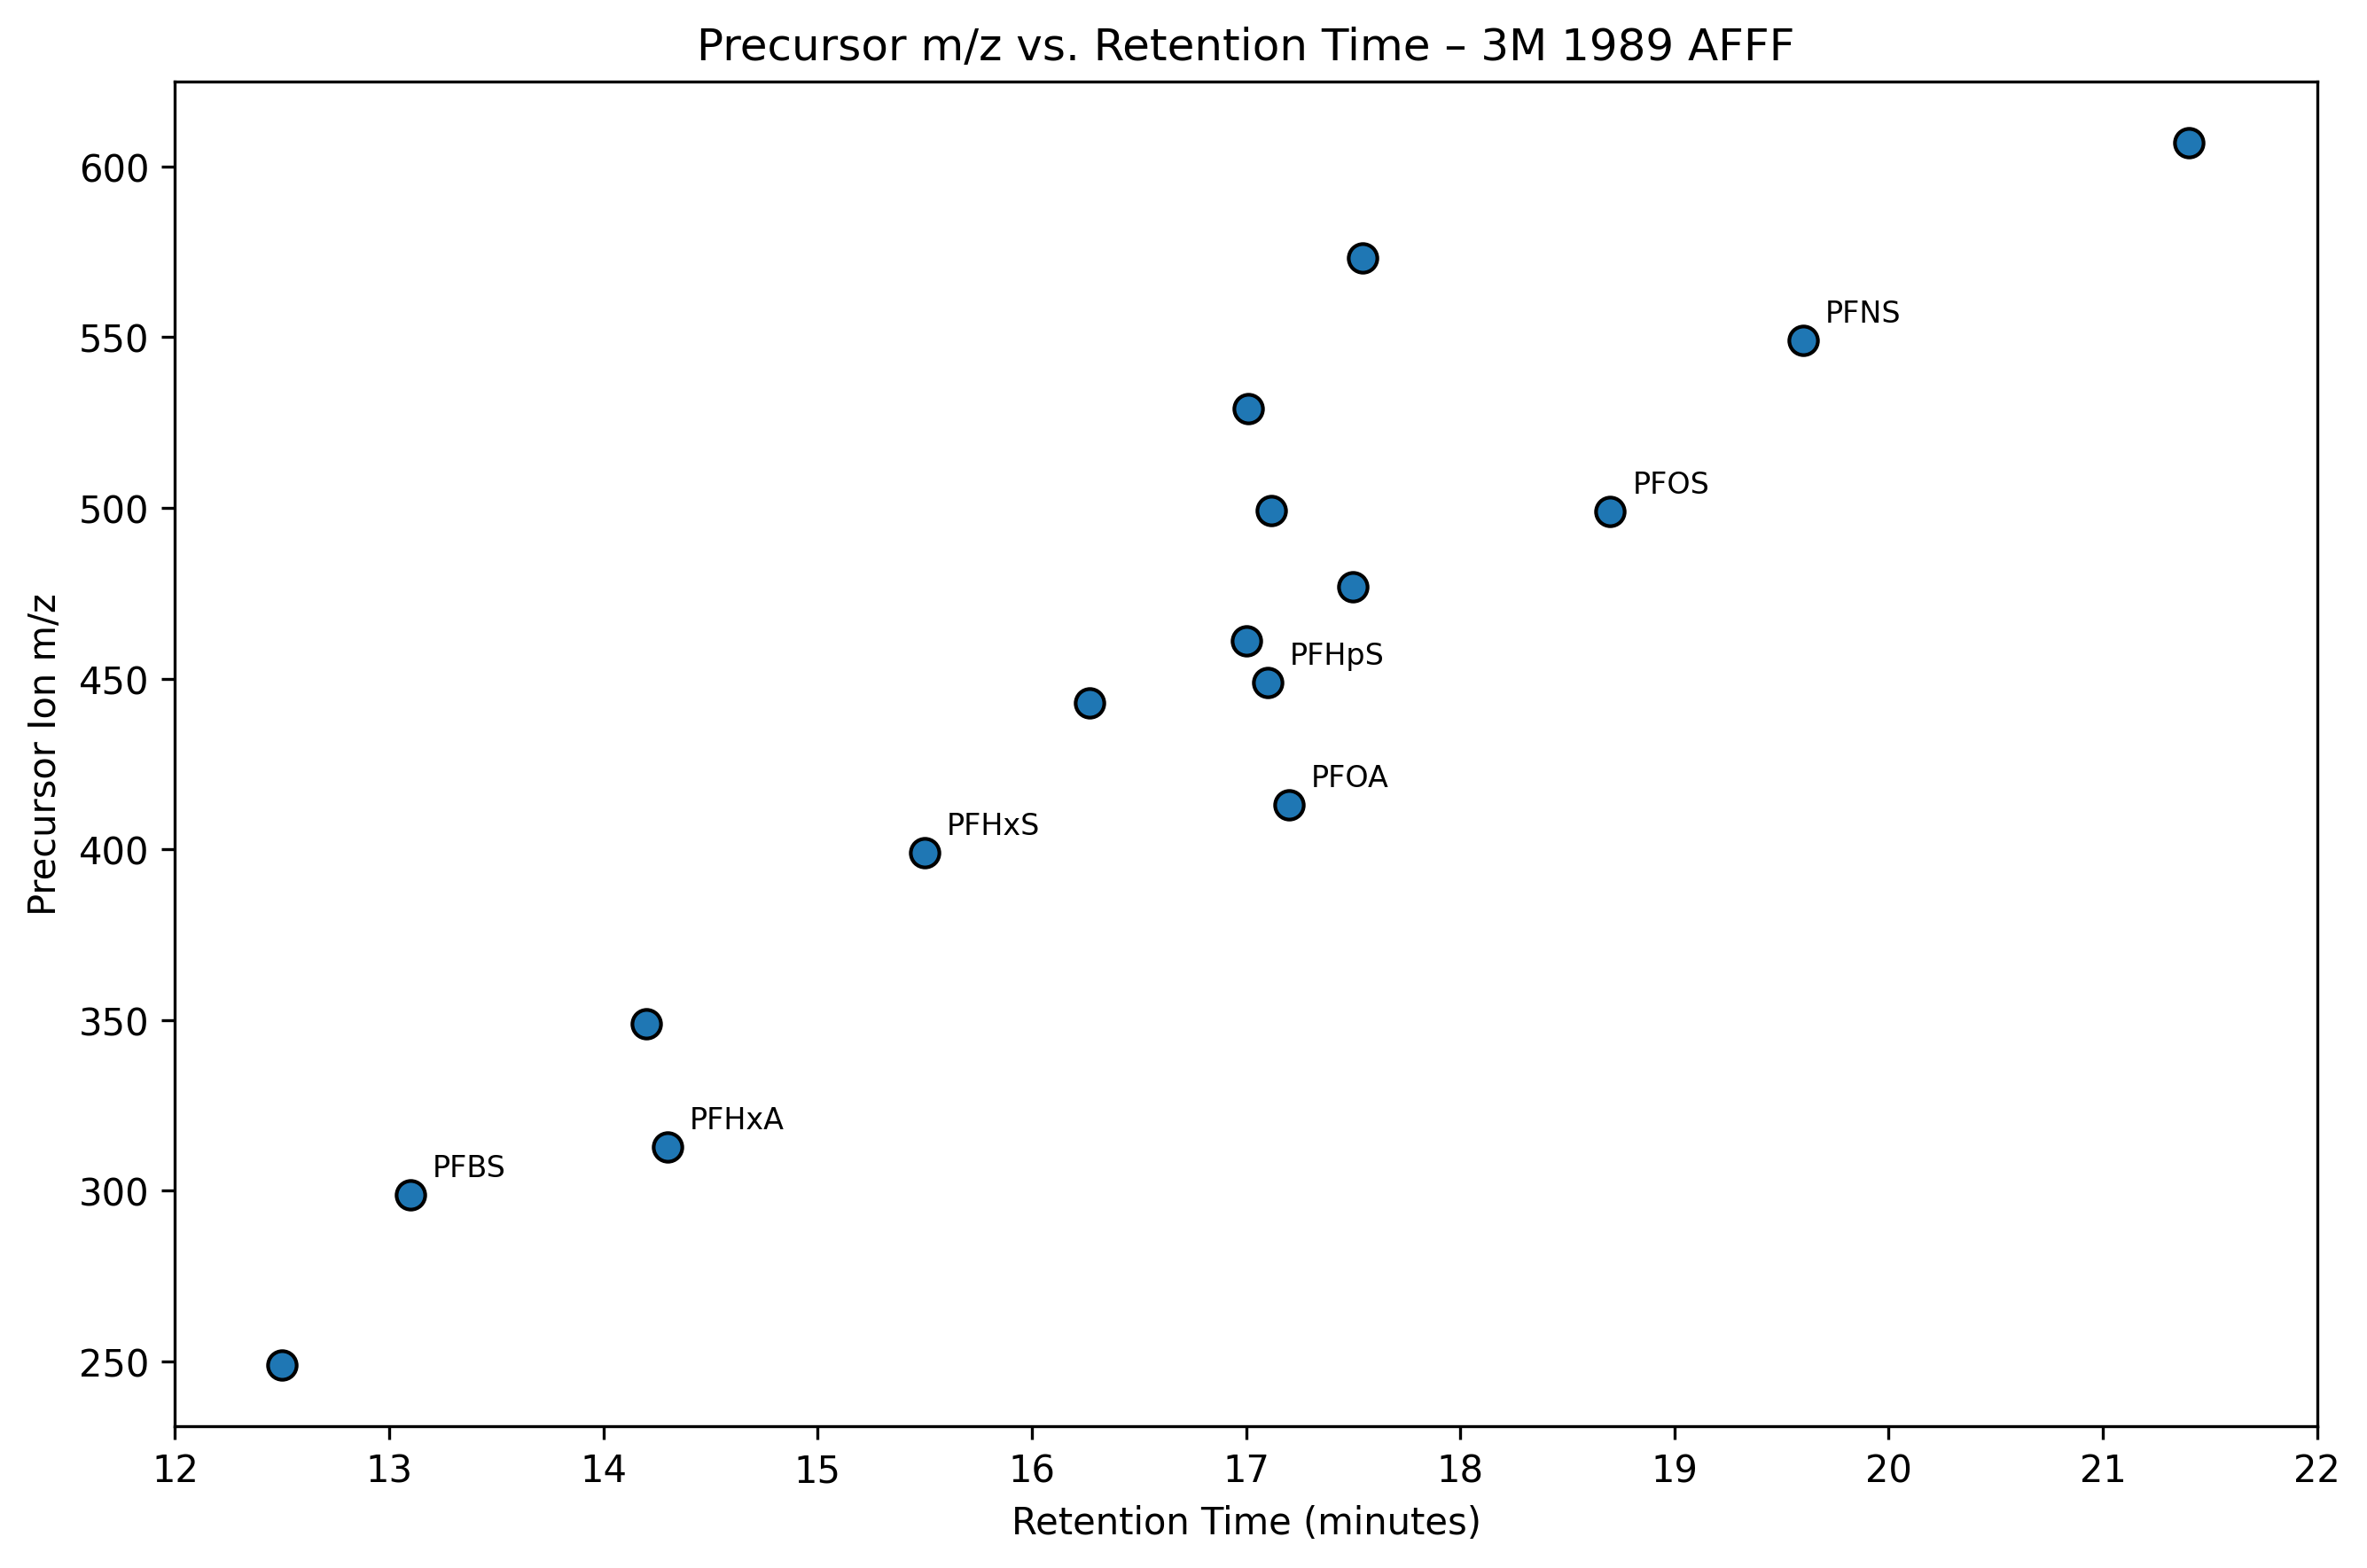

In [220]:
# Plot precursor m/z against chromatographic retention time

labels = {
    "Perfluorobutanesulfonic acid": "PFBS",
    "Perfluorohexanoic acid": "PFHxA",
    "Perfluorohexanesulfonic acid": "PFHxS",
    "Perfluorooctanoic acid": "PFOA",
    "Perfluoroheptanesulfonic acid": "PFHpS",
    "Perfluorooctanesulfonic acid": "PFOS",
    "Perfluorononanesulfonic acid": "PFNS"
}

plt.figure(figsize=(9,6), dpi=300)

plt.scatter(
    sample_df["Retention Time"],
    sample_df["Precursor m/z"],
    s=60,
    edgecolor="black"
)

for _, row in sample_df.iterrows():
    if row["Compound"] in labels:
        plt.annotate(
            labels[row["Compound"]],
            (row["Retention Time"], row["Precursor m/z"]),
            xytext=(6,5),
            textcoords="offset points",
            fontsize=8
        )

plt.title(f"Precursor m/z vs. Retention Time – {selected_sample}")
plt.xlabel("Retention Time (minutes)")
plt.ylabel("Precursor Ion m/z")

# Increase retention-time axis resolution
plt.xticks(np.arange(12, 23, 1))

plt.tight_layout()
plt.show()

#### c) Short- and Long-Chain PFAA Composition

In [221]:
# Classify PFCAs and PFSAs by carbon-chain length
short_chain = {
    "Perfluorohexanoic acid": "PFHxA",           # C6 PFCA
    "Perfluoropropane sulfonate": "PFPrS",       # C3 PFSA
    "Perfluorobutanesulfonic acid": "PFBS",      # C4 PFSA
    "Perfluoropentanesulfonic acid": "PFPeS"     # C5 PFSA
}
long_chain = {
    "Perfluorooctanoic acid": "PFOA",            # C8 PFCA
    "Perfluorohexanesulfonic acid": "PFHxS",     # C6 PFSA
    "Perfluoroheptanesulfonic acid": "PFHpS",    # C7 PFSA
    "Perfluorooctanesulfonic acid": "PFOS",      # C8 PFSA
    "Perfluorononanesulfonic acid": "PFNS"       # C9 PFSA
}

# Assign chain classification
def classify_chain(compound):
    if compound in short_chain:
        return "Short-chain"
    elif compound in long_chain:
        return "Long-chain"
    else:
        return "Other / not classified"
sample_df["Chain Classification"] = (
    sample_df["Compound"].apply(classify_chain)
)

# Count compounds in each category
chain_counts = (
    sample_df["Chain Classification"]
    .value_counts()
    .reindex(
        ["Short-chain", "Long-chain", "Other / not classified"],
        fill_value=0
    )
    .reset_index()
)
chain_counts.columns = [
    "Chain Classification",
    "Number of Compounds"
]

chain_counts["Percentage"] = (
    chain_counts["Number of Compounds"] / len(sample_df) * 100
).round(1)

chain_counts["Percentage"] = (
    chain_counts["Percentage"].astype(str) + "%"
)

display(chain_counts)

,Chain Classification,Number of Compounds,Percentage
0,Short-chain,4,25.0%
1,Long-chain,5,31.2%
2,Other / not classified,7,43.8%


**Results**

The 3M 1989 AFFF sample contained 16 identified PFAS compounds, including commonly studied compounds such as PFOS, PFOA, PFHxS, PFHxA, and PFBS. Precursor m/z values ranged from approximately 249 to 607, while retention times ranged from 12.5 to 21.4 minutes, with higher-mass compounds generally appearing at longer retention times. Of the 16 compounds, 25.0% were classified as short-chain PFAAs (4) and 31.3% as long-chain PFAAs (5), while 43.8% fell outside the PFCA/PFSA chain-length classification (7). 

Overall, examining an individual sample provides a closer look at its specific PFAS composition and analytical characteristics that may be less apparent when considering the database as a whole.

### 2.2.5 Sample-Level Feature Table

In [222]:
import pandas as pd

cursor.execute("""
SELECT
    s.description AS sample_description_group,
    COUNT(DISTINCT c.id) AS compound_count,
    ROUND(AVG(p.precursor_mz),2) AS avg_precursor_mz,
    ROUND(MIN(p.precursor_mz),2) AS min_precursor_mz,
    ROUND(MAX(p.precursor_mz),2) AS max_precursor_mz,
    ROUND(AVG(p.rt_centroid),2) AS avg_retention_time
FROM samples s
JOIN peaks p
    ON s.id = p.sample_id
JOIN compound_fragments cf
    ON p.id = cf.peak_id
JOIN compounds c
    ON cf.compound_id = c.id
GROUP BY
    s.description
ORDER BY
    compound_count DESC;
""")

sample_summary = pd.DataFrame(
    cursor.fetchall(),
    columns=[
        "Sample-Description Group",
        "Compound Count",
        "Avg m/z",
        "Min m/z",
        "Max m/z",
        "Avg Retention Time (min)"
    ]
)

sample_summary

sample_summary.head(10)

,Sample-Description Group,Compound Count,Avg m/z,Min m/z,Max m/z,Avg Retention Time (min)
0,Reference Standard for PFAS,36,486.02,228.97,712.95,13.30
1,3M FC-95 Formulation,31,495.32,198.95,710.92,18.22
2,3M PFOS Technical Mixture,29,470.55,198.95,610.92,17.72
3,3M 1993b AFFF,19,423.00,248.95,571.09,15.89
4,3M 2001 AFFF,17,431.25,248.95,557.07,16.24
5,3M 1998 AFFF,17,422.31,248.95,557.07,15.85
6,3M 1989 AFFF,16,468.14,248.95,606.90,17.35
7,3M 1993a AFFF,15,423.37,248.95,571.09,15.78
8,AFFF Reserve Tank,10,466.18,298.94,548.93,17.56
9,3M FC-129 Formulation,10,471.12,334.00,583.98,19.51


**Results**

The sample-level feature table summarizes PFAS composition and chromatographic characteristics across the 76 sample-description groups. The “Reference Standard for PFAS” group contained the largest number of distinct compounds across its associated records (36), followed by the 3M FC-95 Formulation group (31) and the 3M PFOS Technical Mixture group (29). Among the groups displayed in the summary table, average precursor m/z values ranged from approximately 422 to 495, while average retention times ranged from approximately 13.3 to 19.5 minutes. 

These results demonstrate substantial variation in chemical composition and chromatographic behavior across the represented materials. Because records sharing a description were aggregated, the table characterizes sample-description groups rather than independent physical samples.

### 2.2.6 Construct a Sample-Description-Group–Compound Feature Matrix

Objective: Construct a sample-by-compound feature matrix in which each row represents a sample and each column represents a PFAS compound. The matrix provides a binary representation of compound presence across samples and serves as a foundation for downstream co-occurrence analyses, clustering, and machine learning applications.

In [223]:
import pandas as pd

cursor.execute("""
SELECT DISTINCT
    s.description AS sample_description_group,
    c.name AS compound
FROM samples s
JOIN peaks p
    ON s.id = p.sample_id
JOIN compound_fragments cf
    ON p.id = cf.peak_id
JOIN compounds c
    ON cf.compound_id = c.id;
""")

df = pd.DataFrame(cursor.fetchall(), columns=["Sample-Description Group", "Compound"])

# Construct the complete sample-compound feature matrix
feature_matrix = pd.crosstab(
    df["Sample-Description Group"],
    df["Compound"]
).astype(int)

# Select the 10 most frequently detected compounds
top_compounds = feature_matrix.sum().sort_values(ascending=False).head(10).index

# Create a display matrix containing the top compounds
display_matrix = feature_matrix[top_compounds]

# Rename common PFAS compounds using standard abbreviations
display_matrix = display_matrix.rename(columns={
    "Perfluorooctanesulfonic acid": "PFOS",
    "Perfluorohexanesulfonic acid": "PFHxS",
    "Perfluoroheptanesulfonic acid": "PFHpS",
    "Perfluorobutanesulfonic acid": "PFBS",
    "Perfluoropentanesulfonic acid": "PFPeS",
    "Perfluoropropane sulfonate": "PFPrS",
    "Perfluorohexanoic acid": "PFHxA",
    "Perfluorooctanoic acid": "PFOA",
    "(6E)-1,1,2,2,3,3,4,4,5,5,6,7,8,8,8-pentadecafluorooct-6-ene-1-sulfonic acid": "6E-PFOS*",
    "Keto-perfluorooctane sulfonate": "Keto-PFOS*",
})

# Remove the column index label
display_matrix.columns.name = None

display_matrix

,PFOA,PFOS,PFHxS,PFHpS,PFBS,PFHxA,PFPeS,PFPrS,6E-PFOS*,Keto-PFOS*
Sample-Description Group,,,,,,,,,,
3M 1988 AFFF,0,0,0,0,0,0,0,0,0,0
3M 1989 AFFF,1,1,1,1,1,1,1,1,1,1
3M 1993a AFFF,1,1,1,1,1,1,1,1,1,0
3M 1993b AFFF,1,1,1,1,1,1,1,1,1,1
3M 1998 AFFF,1,1,1,1,1,1,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...
PFAS150 - DTXSID90382620,0,0,0,0,0,0,0,0,0,0
PFAS150 - DTXSID9059832,0,0,0,0,0,0,0,0,0,0
PFAS150 - DTXSID9065443,0,0,0,0,0,0,0,0,0,0


*Note: 6E-PFOS is used as an abbreviated display label for (6E)-1,1,2,2,3,3,4,4,5,5,6,7,8,8,8-pentadecafluorooct-6-ene-1-sulfonic acid. Keto-PFOS is used as an abbreviated display label for Keto-perfluorooctane sulfonate.

**Results**

The binary matrix records whether each PFAS was identified within each sample-description group. It provides a structured representation of compound presence that supports comparison of PFAS composition and calculation of group-level co-occurrence.

Some results include:
- The 3M 1989 AFFF sample contains all ten displayed compounds.
- The Reference Standard for PFAS contains several of the most common compounds but not all of them.
- Many PFAS150 reference compounds contain none of these ten compounds.

The feature matrix provides a simplified view of which PFAS compounds (horizontal columns) are present in each sample (vertical row), allowing samples to be compared based on their detected compounds.

### 2.2.7 Compound Co-occurrence

In [140]:
top_co_occurrence = (
    feature_matrix[top_compounds]
    .T
    .dot(feature_matrix[top_compounds])
)

top_co_occurrence

Compound,Perfluorooctanoic acid,Perfluorooctanesulfonic acid,Perfluorohexanesulfonic acid,Perfluoroheptanesulfonic acid,Perfluorobutanesulfonic acid,Perfluorohexanoic acid,Perfluoropentanesulfonic acid,Perfluoropropane sulfonate,"(6E)-1,1,2,2,3,3,4,4,5,5,6,7,8,8,8-pentadecafluorooct-6-ene-1-sulfonic acid",Keto-perfluorooctane sulfonate
Compound,,,,,,,,,,
Perfluorooctanoic acid,12,10,9,9,8,8,9,7,6,5
Perfluorooctanesulfonic acid,10,12,9,9,8,8,9,7,6,5
Perfluorohexanesulfonic acid,9,9,11,9,8,8,9,7,6,5
Perfluoroheptanesulfonic acid,9,9,9,10,8,8,9,7,6,5
Perfluorobutanesulfonic acid,8,8,8,8,10,7,8,6,6,5
Perfluorohexanoic acid,8,8,8,8,7,9,8,7,5,4
Perfluoropentanesulfonic acid,9,9,9,9,8,8,9,7,6,5
Perfluoropropane sulfonate,7,7,7,7,6,7,7,7,5,4
"(6E)-1,1,2,2,3,3,4,4,5,5,6,7,8,8,8-pentadecafluorooct-6-ene-1-sulfonic acid",6,6,6,6,6,5,6,5,6,5


The co-occurrence matrix summarizes the number of sample-description groups in which each PFAS pair was identified together. Diagonal values represent the total number of groups containing each compound. These values describe overlap within the database and do not establish environmental association or common sources.

**Results**
- PFOA and PFOS were detected together in 10 samples, representing the most frequent compound pair in the dataset.
- PFOA, PFOS, PFHxS, PFHpS, and PFPeS were each detected together in 9 samples, indicating these compounds commonly co-occur across multiple samples.
- PFOA, PFOS, PFHxS, PFHpS, PFBS, and PFHxA showed co-occurrence counts ranging from 8–9 samples, suggesting these PFAS are often found together.
- Perfluoropropane sulfonate (PFPrS) co-occurred with the major PFAS compounds in 6–7 samples, indicating a more limited but still frequent presence.
- The less common compounds, (6E)-1,1,2,2,3,3,4,4,5,5,6,7,8,8,8-pentadecafluorooct-6-ene-1-sulfonic acid and Keto-perfluorooctane sulfonate, exhibited the lowest co-occurrence counts (4–6 samples), suggesting they are detected in a smaller subset of samples.

### 2.2.8 PFAS Composition by Sample Class

In [224]:
cursor.execute("""
SELECT
    nsc.name AS sample_class,
    COUNT(DISTINCT c.id) AS compound_count
FROM samples s
JOIN norm_sample_classes nsc
    ON s.sample_class_id = nsc.id
JOIN peaks p
    ON s.id = p.sample_id
JOIN compound_fragments cf
    ON p.id = cf.peak_id
JOIN compounds c
    ON cf.compound_id = c.id
GROUP BY
    s.description,
    nsc.name
ORDER BY
    nsc.name;
""")

df = pd.DataFrame(
    cursor.fetchall(),
    columns=["Sample Class", "Compound Count"]
)

# Rename analytical standards for clearer presentation
df["Sample Class"] = df["Sample Class"].replace(
    "analytical standard", "reference standard"
)

sample_class_summary = (
    df.groupby("Sample Class")["Compound Count"]
      .agg(["count", "mean", "min", "max"])
      .round(0)
      .rename(columns={
          "count": "Description Groups",
          "mean": "Average Compounds",
          "min": "Minimum",
          "max": "Maximum"
      })
)

sample_class_summary

,Description Groups,Average Compounds,Minimum,Maximum
Sample Class,,,,
aqueous film-forming foam (AFFF),12,10.0,2,19
commercial formulation,3,23.0,10,31
reference standard,61,2.0,1,36


**Results**

The database contained 61 reference-standard, 12 AFFF, and three commercial-formulation description groups. AFFF and commercial-formulation groups generally contained more PFAS than reference-standard groups. However, the strong class imbalance and aggregation by shared description limit direct comparisons among classes.

# 3 MASS SPECTRAL CHARACTERIZATION

## 3.1 Explore MS/MS data

What mass spectral information is available for the detected PFAS compounds in the NIST PFAS database?

Before analyzing fragmentation patterns, it is important to examine the structure of the ms_data table. This section identifies the spectral variables available for each chromatographic peak and describes how the database stores complete mass spectra.

In [225]:
cursor.execute("""
SELECT
    peak_id,
    ms_n,
    scantime,
    base_ion,
    base_int,
    measured_mz,
    measured_intensity
FROM ms_data
LIMIT 1;
""")

df = pd.DataFrame(
    cursor.fetchall(),
    columns=[
        "Peak ID",
        "MS Level",
        "Scan Time",
        "Base Ion (m/z)",
        "Base Ion Intensity",
        "Measured m/z",
        "Measured Intensity"
    ]
)

df

,Peak ID,MS Level,Scan Time,Base Ion (m/z),Base Ion Intensity,Measured m/z,Measured Intensity
0,1,1,16.8224,529.0815,2311.1898,529.0815 530.0845 531.0778,2311.18977520742 125.047514101823 438.075452120501


**Results**
- A representative record from the ms_data table was examined to illustrate how mass spectral data are stored. The spectrum included the scan time, base ion m/z, and base ion intensity.
- The selected spectrum was associated with Peak ID 1 and was acquired at MS level 1 with a scan time of 16.8224 minutes.
- The spectrum had a base ion m/z of 529.0815 with a corresponding base ion intensity of 2311.1898.
- The measured m/z values and their corresponding intensities were stored as paired, space-separated lists within the measured_mz and measured_intensity columns.

Each row in the ms_data table represents one complete mass spectrum. Instead of storing each detected ion in a separate row, the database stores all ion masses and their corresponding intensities together, preserving the full spectral profile for each chromatographic peak. This organization makes it possible to analyze and compare PFAS mass spectra in later sections.

## 3.2 Number of Measured Ions per Spectrum

How many measured ions are detected in each mass spectrum?

This section quantifies the number of detected ions within each spectrum to characterize the complexity of the mass spectral data across the dataset.

Statistic,Value
Count,7194.00
Mean,26.17
Std. Dev.,45.03
Minimum,1.00
25th Percentile,13.00
Median,18.00
75th Percentile,24.00
Maximum,998.00


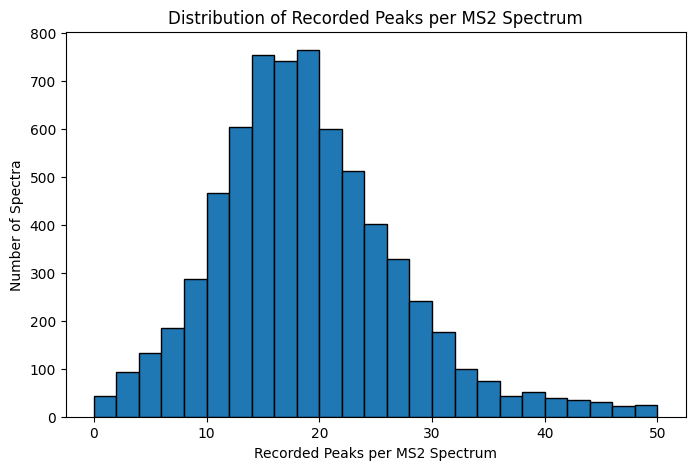

In [227]:
cursor.execute("""
SELECT 
    peak_id,
    measured_mz
FROM ms_data
WHERE measured_mz IS NOT NULL
    AND ms_n = 2
""")

fragment_counts = pd.DataFrame(
    cursor.fetchall(),
    columns=["Peak ID", "Measured m/z"]
)

# Count the number of measured ions stored in each spectrum
fragment_counts["Fragment Count"] = (
    fragment_counts["Measured m/z"]
    .str.split()
    .str.len()
)

# Summary statistics
summary = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Std. Dev.",
        "Minimum",
        "25th Percentile",
        "Median",
        "75th Percentile",
        "Maximum"
    ],
    "Value": [
        len(fragment_counts),
        round(fragment_counts["Fragment Count"].mean(), 2),
        round(fragment_counts["Fragment Count"].std(), 2),
        int(fragment_counts["Fragment Count"].min()),
        int(fragment_counts["Fragment Count"].quantile(0.25)),
        int(fragment_counts["Fragment Count"].median()),
        int(fragment_counts["Fragment Count"].quantile(0.75)),
        int(fragment_counts["Fragment Count"].max())
    ]
})

display(
    summary.style
    .format({"Value": "{:.2f}"})
    .hide(axis="index")
)

# Distribution of measured ions per spectrum
plt.figure(figsize=(8, 5))

plt.hist(
    fragment_counts["Fragment Count"],
    bins=25,
    range=(0, 50),
    edgecolor="black"
)

plt.xlabel("Recorded Peaks per MS2 Spectrum")
plt.ylabel("Number of Spectra")
plt.title("Distribution of Recorded Peaks per MS2 Spectrum")

plt.show()

The analysis was restricted to MS2 spectra to avoid combining different acquisition levels. The histogram displays spectra containing up to 50 measured peaks; spectra exceeding this range were retained in the summary statistics.

**Results**
- A total of 7,194 MS2 spectra were analyzed.
- Spectra contained an average of 26.17 recorded peaks (median = 18), with counts ranging from 1 to 998.
- The middle 50% of spectra contained between 13 and 24 measured peaks.
- Most spectra contained fewer than 30 measured peaks. A smaller number of spectra with high peak counts contributed to a right-skewed distribution.
  
**Interpretation**

The distribution demonstrates variation in the number of measured peaks among MS2 spectra. Most spectra contained relatively few peaks, while a smaller subset contained substantially higher counts. Peak counts provide a descriptive measure of spectral complexity, but the observed differences cannot be attributed solely to compound fragmentation behavior because acquisition conditions and spectral processing may also influence the number of recorded peaks.

## 3.3 Distribution of Measured Ion m/z Values

What is the distribution of measured ion mass-to-charge (m/z) values across the PFAS mass spectra?

This section characterizes the mass-to-charge (m/z) values of detected measured ions to better understand the range and distribution of ions represented within the PFAS mass spectral dataset.

In [228]:
cursor.execute("""
SELECT measured_mz
FROM ms_data
WHERE ms_n = 2;
""")

rows = cursor.fetchall()

measured_mz = []

for row in rows:
    if row[0]:
        measured_mz.extend(
            float(mz)
            for mz in row[0].split()
        )

df_mz = pd.DataFrame(
    measured_mz,
    columns=["Measured m/z"]
)

df_mz.head()

,Measured m/z
0,56.0519
1,58.0651
2,58.0731
3,58.0772
4,72.0842


In [229]:
mz_raw = pd.Series(fragment_mz, dtype=float)

print("Total m/z entries:", len(mz_raw))
print("Nonpositive m/z entries:", (mz_raw <= 0).sum())

Total m/z entries: 188236
Nonpositive m/z entries: 10


In [230]:
#Summary statistics

df_mz = df_mz[df_mz["Measured m/z"] > 0]

summary = pd.DataFrame({
    "Statistic": ["Count", "Mean", "Std. Dev.", "Minimum",
                  "25th Percentile", "Median",
                  "75th Percentile", "Maximum"],
    "Value": [
        len(df_mz),
        round(df_mz["Measured m/z"].mean(),2),
        round(df_mz["Measured m/z"].std(),2),
        round(df_mz["Measured m/z"].min(),2),
        round(df_mz["Measured m/z"].quantile(.25),2),
        round(df_mz["Measured m/z"].median(),2),
        round(df_mz["Measured m/z"].quantile(.75),2),
        round(df_mz["Measured m/z"].max(),2)
    ]
})

display(summary)

,Statistic,Value
0,Count,188226.00
1,Mean,187.48
2,Std. Dev.,144.78
3,Minimum,50.00
4,25th Percentile,80.97
5,Median,119.06
6,75th Percentile,254.98
7,Maximum,1141.93


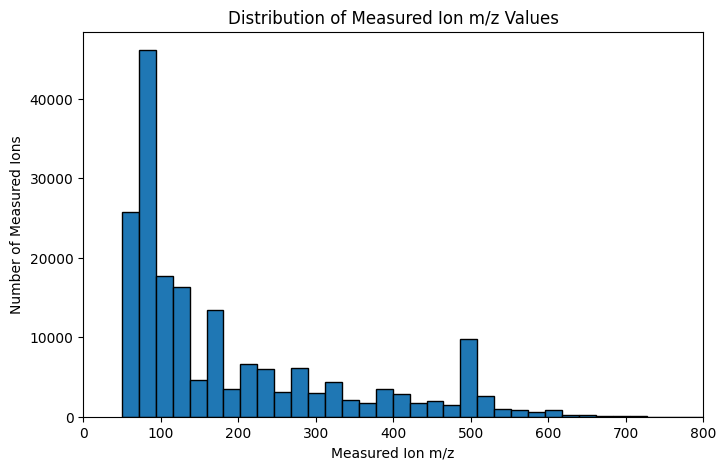

In [231]:
plt.figure(figsize=(8,5))

plt.hist(
    df_mz["Measured m/z"],
    bins=50,
    edgecolor="black"
)

plt.xlabel("Measured Ion m/z")
plt.ylabel("Number of Measured Ions")
plt.title("Distribution of Measured Ion m/z Values")

plt.xlim(0,800)

plt.show()

The analysis was restricted to MS2 spectra and included 188,226 recorded m/z values, excluding 10 nonpositive m/z entries. Values ranged from 50.00 to 1141.93, with a mean of 187.48 and a median of 119.06. The middle 50% of values fell between 80.97 and 254.98. The histogram showed a strongly right-skewed distribution, with the highest frequencies at lower m/z values and a smaller number of observations extending to higher values.

These results summarize the measured m/z values represented in the available MS2 spectra. Prominent histogram bins indicate frequently recorded m/z regions, but do not alone establish shared fragmentation behavior among PFAS compounds. Each recorded peak was counted separately, including repeated observations across spectra.

## 3.4 Distribution of Measured Ion Intensities

What is the distribution of measured ion intensities across the PFAS mass spectra?

This section characterizes the intensity values of detected measured ions to examine the distribution of signal abundances within the PFAS mass spectral dataset.

In [232]:
cursor.execute("""
SELECT measured_intensity
FROM ms_data
WHERE ms_n = 2;
""")

rows = cursor.fetchall()

fragment_intensity = []

for row in rows:
    if row[0]:
        fragment_intensity.extend(
            float(i)
            for i in row[0].split()
        )

df_intensity = pd.DataFrame(
    fragment_intensity,
    columns=["Fragment Intensity"]
)

In [233]:
summary = pd.DataFrame({
    "Statistic": ["Count", "Mean", "Std. Dev.", "Minimum",
                  "25th Percentile", "Median",
                  "75th Percentile", "Maximum"],
    "Value": [
        len(df_intensity),
        round(df_intensity["Fragment Intensity"].mean(),2),
        round(df_intensity["Fragment Intensity"].std(),2),
        round(df_intensity["Fragment Intensity"].min(),2),
        round(df_intensity["Fragment Intensity"].quantile(.25),2),
        round(df_intensity["Fragment Intensity"].median(),2),
        round(df_intensity["Fragment Intensity"].quantile(.75),2),
        round(df_intensity["Fragment Intensity"].max(),2)
    ]
})

display(summary)

,Statistic,Value
0,Count,1.882360e+05
1,Mean,3.196695e+05
2,Std. Dev.,5.010314e+06
3,Minimum,0.000000e+00
4,25th Percentile,9.730000e+00
5,Median,5.548390e+03
6,75th Percentile,2.437626e+04
7,Maximum,5.672020e+08


The analysis was restricted to MS2 spectra. A histogram was not included; the distribution was summarized using descriptive statistics.

**Results**
- A total of 188,236 measured intensity values were analyzed.
- Intensities ranged from 0 to approximately 5.67 × 10⁸, with a mean of 3.20 × 10⁵ and a median of 5.55 × 10³.
- The middle 50% of intensity values ranged from 9.73 to 24,376.26.
- The large difference between the mean and median indicates that a relatively small number of high-intensity measurements contributed disproportionately to the mean.

**Interpretation**

The representative MS2 spectrum illustrates how fragment m/z values and their paired intensities form a spectral profile. Each vertical line represents a recorded peak. The resulting fragmentation pattern can support compound comparison and spectral-similarity analysis after appropriate filtering and normalization.

## 3.5 Representative Mass Spectrum

What does a representative PFAS mass spectrum look like?

This section presents a representative mass spectrum to illustrate the relationship between measured ion mass-to-charge (m/z) values and their corresponding signal intensities within an individual PFAS spectrum.

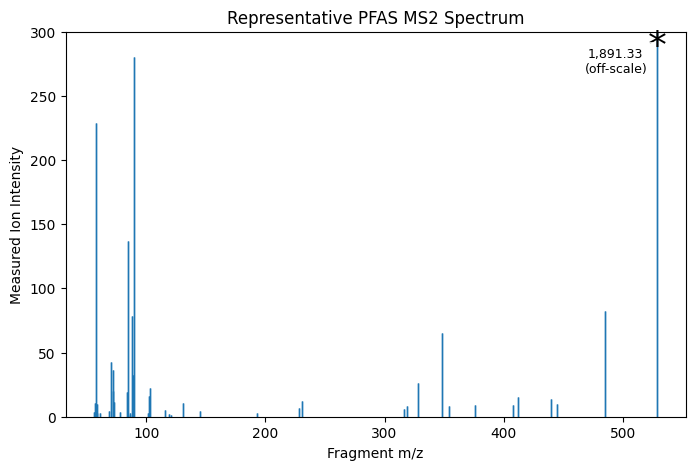

In [234]:
cursor.execute("""
SELECT
    peak_id,
    measured_mz,
    measured_intensity
FROM ms_data
WHERE LENGTH(measured_mz) - LENGTH(REPLACE(measured_mz, ' ', '')) >= 40
    AND ms_n = 2
LIMIT 1;
""")

peak_id, mz_string, intensity_string = cursor.fetchone()

import numpy as np

mz = np.array(mz)
intensity = np.array(intensity)

scale_limit = 300

fig, ax = plt.subplots(figsize=(8,5))

ax.vlines(mz, ymin=0, ymax=intensity, linewidth=1)
ax.set_ylim(0, scale_limit)

plt.vlines(
    mz,
    ymin=0,
    ymax=intensity,
    linewidth=1
)

max_index = np.argmax(intensity)
x_peak = mz[max_index]
y_top = plt.ylim()[1]

plt.text(
    x_peak, y_top * 0.96, "*",
    ha="center", va="center", fontsize=27
)

plt.annotate(
    f"{intensity[max_index]:,.2f}\n(off-scale)",
    xy=(x_peak, y_top * 0.96),
    xytext=(-30, -10),
    textcoords="offset points",
    ha="center",
    va="center",
    fontsize=9,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8)
)

plt.xlabel("Fragment m/z")
plt.ylabel("Measured Ion Intensity")
plt.title("Representative PFAS MS2 Spectrum")
plt.ylim(bottom=0)

plt.show()

**Results**
- An example MS2 spectrum was selected to illustrate the spectral data associated with a single chromatographic peak in the PFAS dataset.
- Each vertical line represents a recorded peak. Its position along the x-axis corresponds to its measured mass-to-charge ratio (m/z), while its height represents measured signal intensity.
- The spectrum contains peaks spanning approximately 50–530 m/z, with a dominant peak near 529 m/z and numerous lower-intensity peaks.
- The dominant peak has a measured intensity of 1,891.33, exceeding the displayed limit of 300. An asterisk and annotation indicate its off-scale value.

**Interpretation**

This example illustrates how measured m/z values and intensities combine to form an MS2 spectral profile. MS2 spectra can contain both fragment ions and surviving precursor ions. Their peak positions and intensity patterns provide information useful for spectral comparison and compound identification, but this visualization does not independently establish compound identity. It illustrates the spectral records underlying the peak-count, m/z, and intensity analyses presented in the previous sections.

# Conclusion



This project established a reproducible SQL and Python workflow for exploring and characterizing the NIST PFAS LC-MS/MS database. The analysis identified 104 database sample records representing 76 unique sample-description groups and characterized PFAS composition, compound co-occurrence, chromatographic behavior, and 7,194 MS2 spectra containing approximately 188,000 recorded peaks.

The workflow transformed relational database records into structured sample-description-group, compound, chromatographic, and spectral features. The project did not train a final AI or machine-learning model; instead, it established the data-processing foundation required for subsequent similarity analysis, clustering, classification, and environmental applications.

The results should be interpreted in view of the database’s strong representation of reference standards, limited number of complex mixtures, and aggregation of records sharing the same sample description. Description-group results therefore should not be interpreted as independent physical-sample counts or as estimates of environmental PFAS prevalence.